# Categorical neighborhoods in no-alarm `{y_prob <= 0.02}`

Index the pile, then for each fraud ask: which rows share **all** of its categorical values?

The neighborhood is the AND of those postings. `n_cell` is occupancy, `n_fraud_cell` is how many of the 1,674 frauds sit in that cell, `rate_cell` is the local fraud rate. `rate_other` drops the query row so a singleton is not counted as enriching itself.

Compare `rate_cell` to the pile rate (~0.28%). A cell at background is overlap given these categoricals. A cell well above background is a pattern HGB still scored near 0. Alarm flags are constant in this region; they do not split the query.

In [1]:
%load_ext autoreload
%autoreload 2

import importlib
import sys
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
from ccf_ml.index import column_index as column_index_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)
importlib.reload(column_index_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_oof_path,
)
from ccf_ml.index import frame_index_from_frame
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(get_repo_root() / "experiments" / "baselines"))
from features import CATEGORICAL_COLUMNS

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "no_alarm_p_le_002_cat_neighbors"
RANK_NOTEBOOK_STEM = "oof_alarm_region_auc"
EXP_NAME = "hgb_baseline"
PROB_COL = "y_prob"
FOLD_COL = "fold_id"
ALARM_SPLIT_COL = "alarm_flag_split"
SCORE_CUT = 0.02
RANK_COL = "rank"
RANK_PCT_COL = "rank_pct"
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
train_features = train_df.drop(columns=[TARGET_COLUMN])
frame = train_features.merge(oof_df, on=ID_COLUMN, how="inner", validate="one_to_one")
if len(frame) != len(train_df) or len(frame) != len(oof_df):
    raise ValueError(
        f"join lost rows: train={len(train_df)} oof={len(oof_df)} joined={len(frame)}"
    )
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
region = frame.loc[(~has_alarm) & (frame[PROB_COL] <= SCORE_CUT)].copy()
n_region = len(region)
n_fraud_region = int((region[TARGET_COLUMN] == 1).sum())
rate_region = n_fraud_region / n_region
print("n_region", n_region)
print("n_fraud", n_fraud_region)
print("rate_region", round(rate_region, 6))
print("categorical columns", list(CATEGORICAL_COLUMNS))
print(DELIMITER_VALUE)
print(region.loc[:, list(CATEGORICAL_COLUMNS)].nunique().to_string())


c:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


n_region 590070
n_fraud 1674
rate_region 0.002837
categorical columns ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
--------------------------------------------------
merchant_category               12
card_type                        5
auth_method                      5
channel                          5
device_type                      8
is_foreign_transaction           1
is_new_merchant                  2
used_vpn                         1
ip_country_mismatch              1
billing_shipping_mismatch        1
is_ai_generated_scam_attempt     1


## Invert every categorical column on this region

`numeric_columns` is empty. Query is `ids_matching` on the fraud's categorical values.

In [2]:
index = frame_index_from_frame(
    region,
    id_column=ID_COLUMN,
    categorical_columns=CATEGORICAL_COLUMNS,
    numeric_columns=(),
)
print("indexed ids", len(index.ids))
n_cat = len(index.columns)
for i in range(n_cat):
    col_index = index.columns[i]
    print(col_index.column, "keys", len(col_index.keys()))


column_index: 100%|██████████| 11/11 [00:02<00:00,  4.83it/s]

indexed ids 590070
merchant_category keys 12
card_type keys 5
auth_method keys 5
channel keys 5
device_type keys 8
is_foreign_transaction keys 1
is_new_merchant keys 2
used_vpn keys 1
ip_country_mismatch keys 1
billing_shipping_mismatch keys 1
is_ai_generated_scam_attempt keys 1


## Query each fraud's categorical fingerprint

Unique fingerprints first, then map back. A fraud must sit in its own cell (`n_fraud_cell >= 1`).

In [3]:
fraud = region.loc[region[TARGET_COLUMN] == 1].copy()
if len(fraud) != n_fraud_region:
    raise ValueError(f"fraud count mismatch: {len(fraud)} vs {n_fraud_region}")
cat_cols = list(CATEGORICAL_COLUMNS)
fingerprints = fraud.drop_duplicates(cat_cols, ignore_index=True)
n_fp = len(fingerprints)
print("unique fingerprints", n_fp)

max_id = int(region[ID_COLUMN].max())
y_by_id = np.full(max_id + 1, -1, dtype=np.int8)
id_arr = region[ID_COLUMN].to_numpy(dtype=np.int64)
y_arr = region[TARGET_COLUMN].to_numpy(dtype=np.int64)
for i in range(n_region):
    y_by_id[int(id_arr[i])] = int(y_arr[i])


def count_fraud(ids: frozenset[int]) -> int:
    total = 0
    for record_id in ids:
        label = int(y_by_id[record_id])
        if label < 0:
            raise ValueError(f"id {record_id} is not in the indexed region")
        total += label
    return total


fp_rows: list[dict[str, object] | None] = [None] * n_fp
for i in tqdm(range(n_fp), desc="cat fingerprint"):
    row = fingerprints.iloc[i]
    values: dict[str, object] = {}
    for j in range(len(CATEGORICAL_COLUMNS)):
        name = CATEGORICAL_COLUMNS[j]
        values[name] = row[name]
    neighbor_ids = index.ids_matching(values=values)
    n_cell = len(neighbor_ids)
    n_fraud_cell = count_fraud(neighbor_ids)
    if n_cell == 0:
        raise ValueError("fingerprint has empty posting")
    if n_fraud_cell < 1:
        raise ValueError("fingerprint cell has no fraud")
    n_other = n_cell - 1
    n_fraud_other = n_fraud_cell - 1
    if n_other > 0:
        rate_other = n_fraud_other / n_other
    else:
        rate_other = float("nan")
    rec: dict[str, object] = {
        "fingerprint_id": i,
        "n_cell": n_cell,
        "n_fraud_cell": n_fraud_cell,
        "rate_cell": n_fraud_cell / n_cell,
        "n_other": n_other,
        "n_fraud_other": n_fraud_other,
        "rate_other": rate_other,
        "enrichment": (n_fraud_cell / n_cell) / rate_region,
    }
    for j in range(len(CATEGORICAL_COLUMNS)):
        name = CATEGORICAL_COLUMNS[j]
        rec[name] = row[name]
    fp_rows[i] = rec

fp_table = pd.DataFrame([row for row in fp_rows if row is not None])
if len(fp_table) != n_fp:
    raise ValueError(f"fingerprint table mismatch: {len(fp_table)} vs {n_fp}")

fraud_profile = fraud.merge(
    fp_table,
    on=cat_cols,
    how="left",
    validate="many_to_one",
)
if fraud_profile["n_cell"].isna().any():
    raise ValueError("some frauds did not match a fingerprint")

rank_path = (
    get_script_table_dir(RANK_NOTEBOOK_STEM) / "no_alarm_p_le_0p02_fraud_ranks.csv"
)
ranks = pd.read_csv(rank_path)
fraud_profile = fraud_profile.merge(
    ranks[[ID_COLUMN, RANK_COL, RANK_PCT_COL]],
    on=ID_COLUMN,
    how="left",
    validate="one_to_one",
)
if fraud_profile[RANK_COL].isna().any():
    raise ValueError("some frauds are missing ranks")

profile_path = tables_dir / "fraud_categorical_neighborhoods.csv"
fp_path = tables_dir / "categorical_fingerprints.csv"
keep_profile = (
    [ID_COLUMN, FOLD_COL, PROB_COL, RANK_COL, RANK_PCT_COL]
    + cat_cols
    + [
        "fingerprint_id",
        "n_cell",
        "n_fraud_cell",
        "rate_cell",
        "n_other",
        "n_fraud_other",
        "rate_other",
        "enrichment",
    ]
)
fraud_profile.loc[:, keep_profile].to_csv(profile_path, index=False)
fp_table.sort_values("n_fraud_cell", ascending=False).to_csv(fp_path, index=False)
print("saved", profile_path)
print("saved", fp_path)

n_isolated = int((fraud_profile["n_cell"] == 1).sum())
n_alone_among_others = int(
    ((fraud_profile["n_cell"] > 1) & (fraud_profile["n_fraud_other"] == 0)).sum()
)
print(DELIMITER_VALUE)
print("frauds with unique fingerprint in region", n_isolated)
print("frauds whose other neighbors are all non-fraud", n_alone_among_others)
print("n_cell")
print(fraud_profile["n_cell"].describe(percentiles=[0.1, 0.5, 0.9]).to_string())
print("rate_cell")
print(fraud_profile["rate_cell"].describe(percentiles=[0.1, 0.5, 0.9]).to_string())
print("enrichment vs region rate")
print(fraud_profile["enrichment"].describe(percentiles=[0.1, 0.5, 0.9]).to_string())
print(DELIMITER_VALUE)
print("cells with most fraud")
print(
    fp_table.sort_values("n_fraud_cell", ascending=False)
    .head(8)
    .loc[:, cat_cols + ["n_cell", "n_fraud_cell", "rate_cell", "enrichment"]]
    .to_string(index=False)
)
print(DELIMITER_VALUE)
print("cells with highest rate among n_cell >= 20")
large = fp_table.loc[fp_table["n_cell"] >= 20]
print(
    large.sort_values("rate_cell", ascending=False)
    .head(8)
    .loc[:, cat_cols + ["n_cell", "n_fraud_cell", "rate_cell", "enrichment"]]
    .to_string(index=False)
)


unique fingerprints 1305


cat fingerprint: 100%|██████████| 1305/1305 [00:05<00:00, 249.51it/s]


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_neighbors\tables\fraud_categorical_neighborhoods.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_neighbors\tables\categorical_fingerprints.csv
--------------------------------------------------
frauds with unique fingerprint in region 28
frauds whose other neighbors are all non-fraud 1025
n_cell
count    1674.000000
mean      262.893668
std       381.580613
min         1.000000
10%         9.000000
50%       112.500000
90%       763.500000
max      2271.000000
rate_cell
count    1674.000000
mean        0.057377
std         0.147688
min         0.000563
10%         0.002809
50%         0.013378
90%         0.111111
max         1.000000
enrichment vs region rate
count    1674.000000
mean       20.224789
std        52.058689
min         0.198363
10%         0.990143
50%         4.715652
9

## Rank in the pile vs local categorical rate

If the worst-ranked frauds live in the same cells as the best-ranked ones, categoricals do not explain the leftover ranking. Per-fold medians have to agree.

better half (lower rank) mean rate_cell 0.065166
worse half mean rate_cell 0.049588
better half mean n_cell 221.9
worse half mean n_cell 303.9
--------------------------------------------------
   fold_id  n_fraud  n_fingerprints  median_n_cell  median_rate_cell  \
0        0      342             318          121.5          0.012579   
1        1      311             290          107.0          0.014286   
2        2      348             320          115.0          0.013794   
3        3      344             324          112.5          0.012658   
4        4      329             315          107.0          0.013605   

   mean_rate_cell  
0        0.058906  
1        0.065715  
2        0.066232  
3        0.047837  
4        0.048514  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_neighbors\tables\categorical_neighborhoods_by_fold.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\Credit

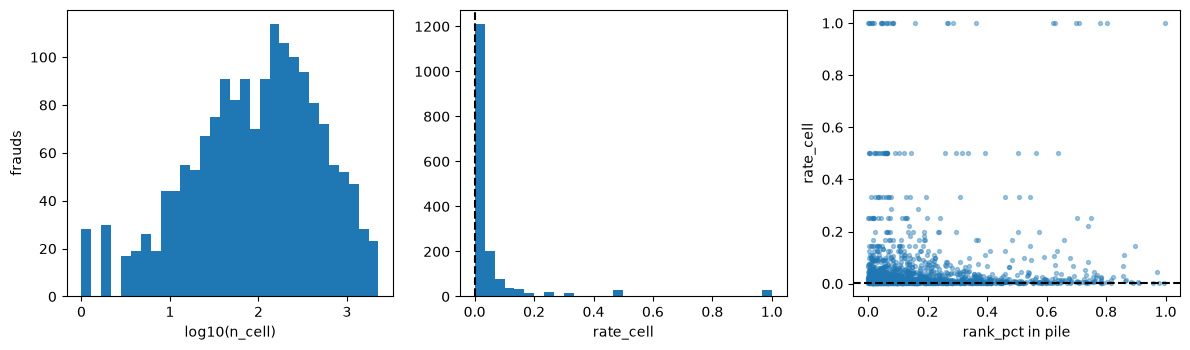

In [4]:
worst = fraud_profile.loc[fraud_profile[RANK_COL] >= fraud_profile[RANK_COL].median()]
best = fraud_profile.loc[fraud_profile[RANK_COL] < fraud_profile[RANK_COL].median()]
print("better half (lower rank) mean rate_cell", round(float(best["rate_cell"].mean()), 6))
print("worse half mean rate_cell", round(float(worst["rate_cell"].mean()), 6))
print("better half mean n_cell", round(float(best["n_cell"].mean()), 1))
print("worse half mean n_cell", round(float(worst["n_cell"].mean()), 1))
print(DELIMITER_VALUE)
fold_rows: list[dict[str, object] | None] = [None] * 5
fold_ids = np.sort(fraud_profile[FOLD_COL].unique())
if len(fold_ids) != 5:
    raise ValueError(f"expected 5 folds, got {len(fold_ids)}")
for i in range(5):
    fold_id = int(fold_ids[i])
    part = fraud_profile.loc[fraud_profile[FOLD_COL] == fold_id]
    fold_rows[i] = {
        FOLD_COL: fold_id,
        "n_fraud": len(part),
        "n_fingerprints": int(part["fingerprint_id"].nunique()),
        "median_n_cell": float(part["n_cell"].median()),
        "median_rate_cell": float(part["rate_cell"].median()),
        "mean_rate_cell": float(part["rate_cell"].mean()),
    }
fold_table = pd.DataFrame([row for row in fold_rows if row is not None])
print(fold_table.round(6))
fold_path = tables_dir / "categorical_neighborhoods_by_fold.csv"
fold_table.to_csv(fold_path, index=False)
print("saved", fold_path)

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="neighborhood")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].hist(np.log10(fraud_profile["n_cell"].to_numpy(dtype=np.float64)), bins=30)
axes[0].set_xlabel("log10(n_cell)")
axes[0].set_ylabel("frauds")
axes[1].hist(fraud_profile["rate_cell"].to_numpy(dtype=np.float64), bins=30)
axes[1].axvline(rate_region, color="black", linestyle="--")
axes[1].set_xlabel("rate_cell")
axes[2].scatter(
    fraud_profile[RANK_PCT_COL].to_numpy(dtype=np.float64),
    fraud_profile["rate_cell"].to_numpy(dtype=np.float64),
    s=8,
    alpha=0.4,
)
axes[2].axhline(rate_region, color="black", linestyle="--")
axes[2].set_xlabel("rank_pct in pile")
axes[2].set_ylabel("rate_cell")
fig.tight_layout()
plot_path = plot_dir / "rate_vs_rank.png"
fig.savefig(plot_path, dpi=140)
print("saved", plot_path)
plt.show()


## Takeaway

1,305 distinct categorical fingerprints among 1,674 frauds. Alarm flags are constant here (`False`); the split is `merchant_category`, `card_type`, `auth_method`, `channel`, `device_type`, `is_new_merchant`.

- **28** frauds are unique on categoricals (`n_cell = 1`). Not copies of anyone in this pile.
- **1,025** sit in a cell whose *other* neighbors are all non-fraud. On categoricals they look like the bulk.
- Median cell has **113** rows and fraud rate **1.34%** vs pile **0.28%** (enrichment **4.7×**). Mean rate is higher (**5.7%**) because tiny cells hit 100%.
- High-occupancy cells (Visa / 3D Secure / Android / groceries–electronics, 500–2,000 rows) hold 5–7 frauds at ~0.3–1.3% — overlap, not a sharp pattern.
- Small cells (`n_cell ≥ 20`) that do spike: Streaming + new merchant, Gift Cards, ATM / POS Terminal, ~8–10% rate, 2–4 frauds. That is a rare pocket, not a mass of the 1,674.
- Worse-ranked half of the pile sits in slightly larger, slightly colder cells (rate 5.0% vs 6.5%). Categoricals weakly track leftover ranking; they do not separate it. Folds agree (median `rate_cell` 0.013).

Categoricals alone do not mark most of these rows as irreducible noise or as a clean missed rule. Most of the 1,674 share a common fingerprint with tens to hundreds of non-frauds. Next query adds numeric percentile keys.

## Singleton-fraud cells (`n_fraud_cell = 1`)

About 1k of the 1.6k frauds are the **only fraud** with that categorical fingerprint. `n_cell` is how many no-alarm `{p ≤ 0.02}` rows share it (1 fraud + `n_cell - 1` non-frauds).

A cell of size 1 has no contrast. A cell of size 10+ has a local numeric distribution we can put the fraud in.

n_solo_fraud 1053
n_cell among singleton-fraud cells
count    1053.000000
mean      126.081671
std       197.959805
min         1.000000
5%          2.000000
10%         5.000000
25%        17.000000
50%        51.000000
75%       154.000000
90%       334.400000
95%       499.800000
max      1777.000000
--------------------------------------------------
 n_cell  n_frauds  share_of_solo
      1        28       0.026591
    2-4        66       0.062678
    5-9        73       0.069326
  10-19       125       0.118708
  20-49       230       0.218424
  50-99       175       0.166192
100-199       161       0.152896
200-499       142       0.134853
   500+        53       0.050332
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_neighbors\tables\solo_fraud_cell_occupancy.csv
--------------------------------------------------
n_cell = 1 (no within-cell contrast) 28
n_cell in [2, 10) (thin contrast) 139
n_cell >= 10 (

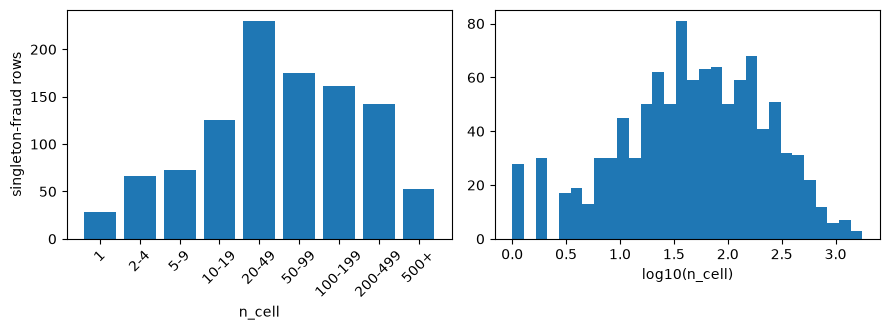

In [5]:
from features import NUMERIC_COLUMNS

solo = fraud_profile.loc[fraud_profile["n_fraud_cell"] == 1].copy()
n_solo = len(solo)
if n_solo == 0:
    raise ValueError("no singleton-fraud cells")
print("n_solo_fraud", n_solo)
print("n_cell among singleton-fraud cells")
print(
    solo["n_cell"].describe(
        percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]
    ).to_string()
)

bounds = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, np.inf])
labels = [
    "1",
    "2-4",
    "5-9",
    "10-19",
    "20-49",
    "50-99",
    "100-199",
    "200-499",
    "500+",
]
bin_id = np.digitize(solo["n_cell"].to_numpy(dtype=np.float64), bounds[1:-1], right=False)
n_bins = len(labels)
occupancy_rows: list[dict[str, object] | None] = [None] * n_bins
for i in range(n_bins):
    in_bin = bin_id == i
    n_in = int(np.sum(in_bin))
    occupancy_rows[i] = {
        "n_cell": labels[i],
        "n_frauds": n_in,
        "share_of_solo": n_in / n_solo,
    }
occupancy = pd.DataFrame([row for row in occupancy_rows if row is not None])
print(DELIMITER_VALUE)
print(occupancy.to_string(index=False))
occupancy_path = tables_dir / "solo_fraud_cell_occupancy.csv"
occupancy.to_csv(occupancy_path, index=False)
print("saved", occupancy_path)

n_no_contrast = int((solo["n_cell"] == 1).sum())
n_small = int(((solo["n_cell"] >= 2) & (solo["n_cell"] < 10)).sum())
n_local = int((solo["n_cell"] >= 10).sum())
print(DELIMITER_VALUE)
print("n_cell = 1 (no within-cell contrast)", n_no_contrast)
print("n_cell in [2, 10) (thin contrast)", n_small)
print("n_cell >= 10 (local numeric CDF usable)", n_local)

solo_plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="solo_fraud_cells")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].bar(occupancy["n_cell"], occupancy["n_frauds"])
axes[0].set_xlabel("n_cell")
axes[0].set_ylabel("singleton-fraud rows")
axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(
    np.log10(solo["n_cell"].to_numpy(dtype=np.float64)),
    bins=30,
)
axes[1].set_xlabel("log10(n_cell)")
fig.tight_layout()
occupancy_plot = solo_plot_dir / "n_cell_distribution.png"
fig.savefig(occupancy_plot, dpi=140)
print("saved", occupancy_plot)
plt.show()


## Within-cell numeric contrast

Categoricals are tied. Remaining features are the numerics. For each singleton-fraud cell, put the fraud in that cell's empirical distribution: average-rank percentile on each numeric. `0.5` is the bulk of the cell. A tail (`≤ 0.1` or `≥ 0.9`) is a one-dimensional handle.

`n_cell = 1` has no contrast. Percentiles are computed for `n_cell ≥ 2`. The usable local CDF is `n_cell ≥ 10`. A perfect 1-d cut means the fraud is the unique min or unique max of some numeric in the cell.

solo cell numerics: 100%|██████████| 1053/1053 [00:03<00:00, 266.48it/s]


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_neighbors\tables\solo_fraud_numeric_percentiles.csv
n_solo 1053
with contrast n_cell >= 2 1025
local n_cell >= 10 886
perfect 1-d cut among n_cell >= 2 403 share 0.3932
perfect 1-d cut among n_cell >= 10 267 share 0.3014
--------------------------------------------------
n_tail_features (n_cell >= 10): count of numerics with pct in [0, 0.1] U [0.9, 1]
0     45
1    175
2    228
3    217
4    135
5     63
6     19
7      4
share with zero tail numerics 0.0508
share with at least one tail numeric 0.9492
share with at least three tail numerics 0.4944
--------------------------------------------------
               column  median_pct  mean_abs_dev_from_mid  share_in_tail
          day_of_week      0.5034                 0.2468         0.2472
 hours_since_last_txn      0.4412                 0.2635         0.2280
       velocity_score      0.6881                 0.256

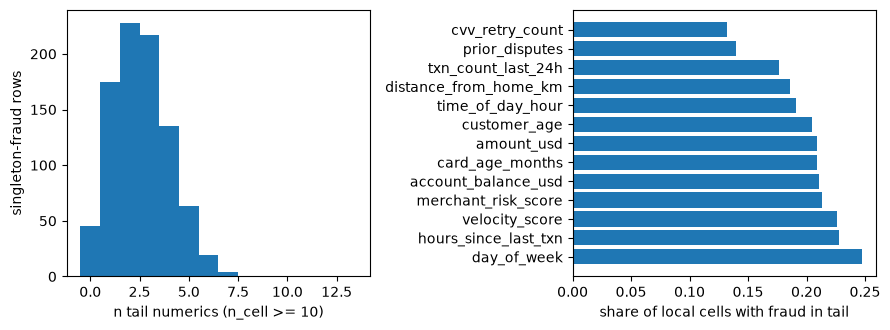

In [6]:
n_num = len(NUMERIC_COLUMNS)
max_id = int(region[ID_COLUMN].max())
num_by_id = np.full((max_id + 1, n_num), np.nan, dtype=np.float64)
id_arr = region[ID_COLUMN].to_numpy(dtype=np.int64)
for j in range(n_num):
    name = NUMERIC_COLUMNS[j]
    col_vals = region[name].to_numpy(dtype=np.float64)
    num_by_id[id_arr, j] = col_vals

TAIL = 0.1
MIN_LOCAL = 10
solo_ids = solo[ID_COLUMN].to_numpy(dtype=np.int64)
n_solo = len(solo)
pct_block = np.full((n_solo, n_num), np.nan, dtype=np.float64)
n_tail = np.full(n_solo, -1, dtype=np.int64)
has_perfect_cut = np.zeros(n_solo, dtype=bool)
n_cell_arr = solo["n_cell"].to_numpy(dtype=np.int64)

for i in tqdm(range(n_solo), desc="solo cell numerics"):
    row = solo.iloc[i]
    values: dict[str, object] = {}
    for j in range(len(CATEGORICAL_COLUMNS)):
        name = CATEGORICAL_COLUMNS[j]
        values[name] = row[name]
    neighbor_ids = index.ids_matching(values=values)
    if len(neighbor_ids) != int(n_cell_arr[i]):
        raise ValueError(
            f"cell size mismatch for id {int(row[ID_COLUMN])}: "
            f"{len(neighbor_ids)} vs {int(n_cell_arr[i])}"
        )
    n_cell = len(neighbor_ids)
    if n_cell < 2:
        continue
    nid = np.fromiter(neighbor_ids, dtype=np.int64, count=n_cell)
    block = num_by_id[nid]
    fraud_id = int(row[ID_COLUMN])
    fraud_vec = num_by_id[fraud_id]
    n_tail_i = 0
    perfect_i = False
    for j in range(n_num):
        col_vals = block[:, j]
        fv = fraud_vec[j]
        n_lt = int(np.sum(col_vals < fv))
        n_eq = int(np.sum(col_vals == fv))
        pct = (n_lt + 0.5 * n_eq) / n_cell
        pct_block[i, j] = pct
        if pct <= TAIL or pct >= (1.0 - TAIL):
            n_tail_i += 1
        others = col_vals[nid != fraud_id]
        n_other_lt = int(np.sum(others < fv))
        n_other_gt = int(np.sum(others > fv))
        n_other_eq = int(np.sum(others == fv))
        if n_other_eq == 0 and (n_other_lt == 0 or n_other_gt == 0):
            perfect_i = True
    n_tail[i] = n_tail_i
    has_perfect_cut[i] = perfect_i

pct_frame = pd.DataFrame(pct_block, columns=list(NUMERIC_COLUMNS))
pct_frame[ID_COLUMN] = solo_ids
pct_frame["n_cell"] = n_cell_arr
pct_frame["n_tail_features"] = n_tail
pct_frame["perfect_1d_cut"] = has_perfect_cut
pct_path = tables_dir / "solo_fraud_numeric_percentiles.csv"
pct_frame.to_csv(pct_path, index=False)
print("saved", pct_path)

has_contrast = n_cell_arr >= 2
local = n_cell_arr >= MIN_LOCAL
print("n_solo", n_solo)
print("with contrast n_cell >= 2", int(np.sum(has_contrast)))
print("local n_cell >= 10", int(np.sum(local)))
print(
    "perfect 1-d cut among n_cell >= 2",
    int(np.sum(has_perfect_cut & has_contrast)),
    "share",
    round(float(np.mean(has_perfect_cut[has_contrast])), 4),
)
print(
    "perfect 1-d cut among n_cell >= 10",
    int(np.sum(has_perfect_cut & local)),
    "share",
    round(float(np.mean(has_perfect_cut[local])), 4),
)

print(DELIMITER_VALUE)
print("n_tail_features (n_cell >= 10): count of numerics with pct in [0, 0.1] U [0.9, 1]")
print(
    pd.Series(n_tail[local]).value_counts().sort_index().to_string()
)
print(
    "share with zero tail numerics",
    round(float(np.mean(n_tail[local] == 0)), 4),
)
print(
    "share with at least one tail numeric",
    round(float(np.mean(n_tail[local] >= 1)), 4),
)
print(
    "share with at least three tail numerics",
    round(float(np.mean(n_tail[local] >= 3)), 4),
)

dev_rows: list[dict[str, object] | None] = [None] * n_num
for j in range(n_num):
    pcts = pct_block[local, j]
    if pcts.size == 0:
        raise ValueError("no local cells")
    abs_dev = np.abs(pcts - 0.5)
    tail_share = float(np.mean((pcts <= TAIL) | (pcts >= (1.0 - TAIL))))
    dev_rows[j] = {
        "column": NUMERIC_COLUMNS[j],
        "median_pct": float(np.median(pcts)),
        "mean_abs_dev_from_mid": float(np.mean(abs_dev)),
        "share_in_tail": tail_share,
    }
dev_table = pd.DataFrame([row for row in dev_rows if row is not None])
dev_table = dev_table.sort_values("share_in_tail", ascending=False)
print(DELIMITER_VALUE)
print(dev_table.round(4).to_string(index=False))
dev_path = tables_dir / "solo_fraud_numeric_tail_by_column.csv"
dev_table.to_csv(dev_path, index=False)
print("saved", dev_path)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].hist(n_tail[local], bins=np.arange(-0.5, n_num + 1.5, 1.0))
axes[0].set_xlabel("n tail numerics (n_cell >= 10)")
axes[0].set_ylabel("singleton-fraud rows")
order = np.arange(n_num)
axes[1].barh(
    np.arange(len(dev_table)),
    dev_table["share_in_tail"].to_numpy(dtype=np.float64),
)
axes[1].set_yticks(np.arange(len(dev_table)))
axes[1].set_yticklabels(list(dev_table["column"]))
axes[1].set_xlabel("share of local cells with fraud in tail")
fig.tight_layout()
contrast_plot = solo_plot_dir / "numeric_within_cell_contrast.png"
fig.savefig(contrast_plot, dpi=140)
print("saved", contrast_plot)
plt.show()


## Takeaway: singleton-fraud cells

**1,053** frauds are the only fraud with that categorical fingerprint (the ~1k). `n_cell` is 1 fraud plus the non-frauds that share it.

Occupancy: median **51** rows (mean 126, max 1,777). **28** cells have no neighbor. **139** have 2–9 rows (thin). **886 (84%)** have `n_cell ≥ 10`, enough to estimate a local numeric CDF.

That is enough *sample* to ask whether numerics separate the fraud from its cell. It is not enough *signal* for a clean rule.

With 13 numerics, a point dropped at random into a cell has ~20% chance to land in each feature's 10% tails, so ~95% chance of at least one tail. Observed: **94.9%**. Share with ≥3 tails: **49%**, same as `Binomial(13, 0.2)`. `share_in_tail` per column sits on ~0.20. The tail count is the null.

What is not the null: **`velocity_score` and `merchant_risk_score`**. Median percentile of the fraud in its cell is **0.69** on both (0.50 would be the bulk). `customer_age` 0.62. `cvv_retry_count` / `prior_disputes` barely move (almost everyone is 0).

A perfect 1-d cut (unique min or max on some numeric) happens in **30%** of cells with `n_cell ≥ 10` — in the range of chance for unique extrema, not a discovered splitter.

So: most of these 1k cells are large enough to look inside. The fraud is usually a typical numeric draw from that cell, sitting a bit high on velocity and merchant risk. Discrimination, if any, is a mild shift on those two, not a categorical-cell × threshold rule.